# Pandas Case Study: TechMart E-Commerce Analysis

## Scenario

You have been hired as a Data Analyst at **TechMart**, an online electronics retailer. The company wants to understand their sales performance, customer behavior, and identify opportunities for growth.

You have been given three datasets:
1. **Orders** - Transaction records
2. **Customers** - Customer information
3. **Products** - Product catalog

Your task is to clean, merge, and analyze this data to provide actionable insights.

---

## Skills Tested

| Module | Concepts |
|--------|----------|
| **07a** | Loading data, viewing data, basic info, value_counts |
| **07b** | Filtering, sorting, missing values, duplicates, groupby, merging |
| **07c** | Apply, datetime operations, string operations, new columns, pivot tables, visualization |

---

## Instructions

1. Complete each task in the provided code cells
2. Run your code to verify it works
3. Answer the analysis questions based on your results
4. Expected outputs are provided to help you verify your answers

**Estimated Time:** 2-3 hours

---

# Part 0: Import library and load dataset


In [52]:
import pandas as pd
import numpy as np

---

# Part 1: Data Exploration (07a Concepts)

Before any analysis, you need to understand your data.

## Task 1.1: Explore the Orders Data

1. Display the first 10 rows of the orders DataFrame
2. Display the last 5 rows
3. Display 5 random rows

In [53]:
# Your code here
df_product = pd.read_csv('../../00-data/products.csv')
df_customer = pd.read_csv('../../00-data/customers.csv')
df_orders = pd.read_csv('../../00-data/orders.csv')

In [54]:
df_orders.sample(5)

,order_id,customer_id,product_id,quantity,order_date,status
94,1095,136,101,1.0,2024-03-05,Processing
363,1364,94,106,2.0,2024-12-07,Shipped
102,1103,36,117,1.0,2024-05-18,Completed
108,1109,19,122,1.0,2024-02-10,Processing
325,1326,39,101,2.0,2024-01-04,Processing


## Task 1.2: Basic Information

1. What are the dimensions (shape) of each DataFrame?
2. What are the data types of columns in the orders DataFrame?
3. Use `.info()` on the orders DataFrame - how many non-null values are in each column?

In [55]:
# Your code here


## Task 1.3: Statistical Summary

1. Use `.describe()` on the products DataFrame
2. What is the average product price? What is the most expensive product price?

In [56]:
# Your code here


In [57]:
df

,product_id,product_name,category,price,cost
0,101,"Laptop Pro 15""",Laptops,1299,800
1,102,"Laptop Air 13""",Laptops,999,650
2,103,Desktop Tower,Desktops,899,550
3,104,Desktop Mini,Desktops,599,380
4,105,Wireless Mouse,Accessories,49,20
5,106,Gaming Mouse,Accessories,79,35
6,107,Mechanical Keyboard,Accessories,129,60
7,108,Wireless Keyboard,Accessories,89,40
8,109,"Monitor 27""",Monitors,349,200
9,110,"Monitor 32""",Monitors,449,270


In [58]:
# df.groupby('')

**Expected Answer:** Average price is $268.44, Maximum price is $1,299

## Task 1.4: Value Counts

1. How many orders are in each status category?
2. How many products are in each category?
3. What is the distribution of customer membership types?

In [59]:
# Your code here


---

# Part 2: Data Cleaning (07b Concepts)

Real data is messy. Let's clean it up!

## Task 2.1: Handle Missing Values

1. How many missing values are in each column of the orders DataFrame?
2. For the `quantity` column: fill missing values with the median quantity
3. For the `status` column: fill missing values with 'Unknown'
4. Verify there are no more missing values in orders

In [60]:
# Your code here
df_orders.isna().sum()

order_id       0
customer_id    0
product_id     0
quantity       8
order_date     0
status         7
dtype: int64

In [61]:
df_orders.fillna({'quantity':df_orders['quantity'].median()},inplace=True)

In [62]:
df_orders.fillna({'status':'unknown'},inplace=True)

In [63]:
df_orders.isna().sum()

order_id       0
customer_id    0
product_id     0
quantity       0
order_date     0
status         0
dtype: int64

## Task 2.2: Handle Duplicates

1. How many duplicate rows are in the orders DataFrame?
2. Remove the duplicate rows (keep the first occurrence)
3. Verify the duplicates were removed - what is the new shape?

In [64]:
# Your code here
df_orders.duplicated().sum()

np.int64(10)

In [65]:
df_orders.drop_duplicates(keep='first',inplace=True)

In [66]:
df_orders.duplicated().sum()

np.int64(0)

**Expected Answer:** 10 duplicate rows, final shape should be (500, 6)

## Task 2.3: Handle Missing Values in Customers

1. Check for missing values in the customers DataFrame
2. Fill missing membership values with 'Basic' (the most common type)
3. Verify no missing values remain

In [67]:
# Your code here
df_customer.isna().sum()

customer_id    0
first_name     0
last_name      0
email          0
city           0
join_date      0
membership     5
region         0
dtype: int64

In [68]:
df_customer.fillna({'membership':'Basic'},inplace=True)

In [69]:
df_customer['membership'].value_counts()

membership
Basic      79
Premium    39
Gold       32
Name: count, dtype: int64

In [70]:
df_customer.isna().sum()

customer_id    0
first_name     0
last_name      0
email          0
city           0
join_date      0
membership     0
region         0
dtype: int64

---

# Part 3: Data Merging (07b Concepts)

Combine the three datasets to enable comprehensive analysis.

## Task 3.1: Merge Orders with Products

1. Merge the `orders` DataFrame with the `products` DataFrame on `product_id`
2. Use an inner join
3. Store the result in a variable called `orders_products`
4. Display the first 5 rows and the shape

In [71]:
df_customer.columns, df_orders.columns, df_product.columns

(Index(['customer_id', 'first_name', 'last_name', 'email', 'city', 'join_date',
        'membership', 'region'],
       dtype='object'),
 Index(['order_id', 'customer_id', 'product_id', 'quantity', 'order_date',
        'status'],
       dtype='object'),
 Index(['product_id', 'product_name', 'category', 'price', 'cost'], dtype='object'))

In [80]:
# Your code here
order_products = pd.merge(df_orders,df_product,on='product_id')
order_products.head()

,order_id,customer_id,product_id,quantity,order_date,status,product_name,category,price,cost
0,1001,2,113,1.0,2024-04-12,Shipped,Webcam 4K,Accessories,149,70
1,1002,128,102,1.0,2024-12-14,Completed,"Laptop Air 13""",Laptops,999,650
2,1003,84,119,1.0,2024-09-27,Completed,Earbuds Sport,Audio,99,45
3,1004,140,119,1.0,2024-04-16,Completed,Earbuds Sport,Audio,99,45
4,1005,124,104,1.0,2024-03-12,Processing,Desktop Mini,Desktops,599,380


In [77]:
order_products.head()

,order_id,customer_id,product_id,quantity,order_date,status,product_name,category,price,cost
0,1001,2,113,1.0,2024-04-12,Shipped,Webcam 4K,Accessories,149,70
1,1002,128,102,1.0,2024-12-14,Completed,"Laptop Air 13""",Laptops,999,650
2,1003,84,119,1.0,2024-09-27,Completed,Earbuds Sport,Audio,99,45
3,1004,140,119,1.0,2024-04-16,Completed,Earbuds Sport,Audio,99,45
4,1005,124,104,1.0,2024-03-12,Processing,Desktop Mini,Desktops,599,380


In [78]:
order_products.shape

(500, 10)

## Task 3.2: Create Complete Dataset

1. Merge `orders_products` with the `customers` DataFrame on `customer_id`
2. Use an inner join
3. Store the result in a variable called `df`
4. Display the columns and shape

In [81]:
# Your code here
df = pd.merge(order_products,df_customer,on='customer_id')

In [82]:
df.columns, df.shape

(Index(['order_id', 'customer_id', 'product_id', 'quantity', 'order_date',
        'status', 'product_name', 'category', 'price', 'cost', 'first_name',
        'last_name', 'email', 'city', 'join_date', 'membership', 'region'],
       dtype='object'),
 (500, 17))

**Expected Answer:** The merged DataFrame should have 500 rows and 17 columns

---

# Part 4: Feature Engineering (07c Concepts)

Create new columns to enable deeper analysis.

## Task 4.1: Calculate Revenue and Profit

1. Create a column `revenue` = price * quantity
2. Create a column `profit` = (price - cost) * quantity
3. Display the first 5 rows showing order_id, product_name, price, quantity, revenue, profit

In [85]:
# Your code here
df['revenue'] = df['price']*df['quantity']
df['profit'] = (df['price']-df['cost'])*df['quantity']

In [86]:
df.head(1)

,order_id,customer_id,product_id,quantity,order_date,status,product_name,category,price,cost,first_name,last_name,email,city,join_date,membership,region,revenue,profit
0,1001,2,113,1.0,2024-04-12,Shipped,Webcam 4K,Accessories,149,70,Jennifer,Lopez,customer2@email.com,Dallas,2023-04-26,Premium,South,149.0,79.0


In [88]:
df.loc[:,['order_id', 'product_name', 'price', 'quantity', 'revenue', 'profit']].head()

,order_id,product_name,price,quantity,revenue,profit
0,1001,Webcam 4K,149,1.0,149.0,79.0
1,1002,"Laptop Air 13""",999,1.0,999.0,349.0
2,1003,Earbuds Sport,99,1.0,99.0,54.0
3,1004,Earbuds Sport,99,1.0,99.0,54.0
4,1005,Desktop Mini,599,1.0,599.0,219.0


## Task 4.2: DateTime Feature Engineering

Using the `order_date` column, create the following new columns:
1. `order_month` - the month number (1-12)
2. `order_quarter` - the quarter (1-4)
3. `order_day_name` - the day of the week name (Monday, Tuesday, etc.)
4. `is_weekend` - True if Saturday or Sunday, False otherwise

Display the first 10 rows showing order_date and these new columns.

In [90]:
df['order_date']

0      2024-04-12
1      2024-12-14
2      2024-09-27
3      2024-04-16
4      2024-03-12
          ...    
495    2024-11-20
496    2024-01-04
497    2024-01-16
498    2024-10-06
499    2024-12-01
Name: order_date, Length: 500, dtype: object

In [91]:
# Your code here
df['order_date'] = pd.to_datetime(df['order_date'])

In [94]:
df['order_month'] = df['order_date'].dt.month
df['order_quarter'] = df['order_date'].dt.quarter
df['order_day_name'] = df['order_date'].dt.day_name()
df['is_weekend'] = df['order_day_name'].isin(['Saturday','Sunday'])

In [95]:
df[['order_date','order_month','order_quarter','order_day_name','is_weekend']].head()

,order_date,order_month,order_quarter,order_day_name,is_weekend
0,2024-04-12,4,2,Friday,False
1,2024-12-14,12,4,Saturday,True
2,2024-09-27,9,3,Friday,False
3,2024-04-16,4,2,Tuesday,False
4,2024-03-12,3,1,Tuesday,False


## Task 4.3: String Operations - Create Full Name

1. Create a column `full_name` by combining first_name and last_name with a space
2. Create a column `email_domain` by extracting the domain from the email (everything after @)
3. Display 5 sample rows showing first_name, last_name, full_name, email, email_domain

In [96]:
df.columns

Index(['order_id', 'customer_id', 'product_id', 'quantity', 'order_date',
       'status', 'product_name', 'category', 'price', 'cost', 'first_name',
       'last_name', 'email', 'city', 'join_date', 'membership', 'region',
       'revenue', 'profit', 'order_month', 'order_quarter', 'order_day_name',
       'is_weekend'],
      dtype='object')

In [97]:
# Your code here
df['full_name'] = df['first_name'] + ' ' + df['last_name']
df['email_domain'] = df['email'].str.split('@').str[1]

In [98]:
df.columns

Index(['order_id', 'customer_id', 'product_id', 'quantity', 'order_date',
       'status', 'product_name', 'category', 'price', 'cost', 'first_name',
       'last_name', 'email', 'city', 'join_date', 'membership', 'region',
       'revenue', 'profit', 'order_month', 'order_quarter', 'order_day_name',
       'is_weekend', 'full_name', 'email_domain'],
      dtype='object')

In [100]:
df[['first_name', 'last_name', 'full_name', 'email', 'email_domain']].head()

,first_name,last_name,full_name,email,email_domain
0,Jennifer,Lopez,Jennifer Lopez,customer2@email.com,email.com
1,Jessica,Smith,Jessica Smith,customer128@email.com,email.com
2,Robert,Rodriguez,Robert Rodriguez,customer84@email.com,email.com
3,John,Rodriguez,John Rodriguez,customer140@email.com,email.com
4,Patricia,Rodriguez,Patricia Rodriguez,customer124@email.com,email.com


## Task 4.4: Apply Function - Categorize Revenue

Create a function that categorizes orders by revenue:
- 'Low': revenue < 100
- 'Medium': 100 <= revenue < 500
- 'High': 500 <= revenue < 1000
- 'Premium': revenue >= 1000

Apply this function to create a `revenue_category` column.

In [105]:
df.columns

Index(['order_id', 'customer_id', 'product_id', 'quantity', 'order_date',
       'status', 'product_name', 'category', 'price', 'cost', 'first_name',
       'last_name', 'email', 'city', 'join_date', 'membership', 'region',
       'revenue', 'profit', 'order_month', 'order_quarter', 'order_day_name',
       'is_weekend', 'full_name', 'email_domain'],
      dtype='object')

In [107]:
def cat_rev(rev):
    if rev <100:
        return 'low'
    elif rev < 500:
        return 'medium'
    elif rev < 1000:
        return 'high'
    else:
        return 'premium'

In [108]:
# Your code here
df['revenue_category'] = df['revenue'].apply(cat_rev)

In [110]:
df['revenue_category'].value_counts()

revenue_category
medium     195
low        177
high        65
premium     63
Name: count, dtype: int64

---

# Part 5: Filtering and Sorting (07b Concepts)

## Task 5.1: Filter by Single Condition

1. Find all orders with revenue greater than $1,000
2. How many such orders are there?
3. What is the total revenue from these high-value orders?

In [111]:
# Your code here
high_value = df[df['revenue']>1000]
high_value

,order_id,customer_id,product_id,quantity,order_date,status,product_name,category,price,cost,...,region,revenue,profit,order_month,order_quarter,order_day_name,is_weekend,full_name,email_domain,revenue_category
10,1011,74,110,3.0,2024-11-26,Completed,"Monitor 32""",Monitors,449,270,...,East,1347.0,537.0,11,4,Tuesday,False,Thomas Davis,email.com,premium
24,1025,90,101,1.0,2024-11-09,Completed,"Laptop Pro 15""",Laptops,1299,800,...,West,1299.0,499.0,11,4,Saturday,True,Joseph Williams,email.com,premium
32,1033,21,104,2.0,2024-07-06,Completed,Desktop Mini,Desktops,599,380,...,South,1198.0,438.0,7,3,Saturday,True,David Rodriguez,email.com,premium
48,1049,62,101,1.0,2024-03-29,Cancelled,"Laptop Pro 15""",Laptops,1299,800,...,South,1299.0,499.0,3,1,Friday,False,David Lopez,email.com,premium
57,1058,76,101,2.0,2024-09-20,Cancelled,"Laptop Pro 15""",Laptops,1299,800,...,East,2598.0,998.0,9,3,Friday,False,Sarah Hernandez,email.com,premium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
430,1431,76,102,2.0,2024-05-26,Processing,"Laptop Air 13""",Laptops,999,650,...,East,1998.0,698.0,5,2,Sunday,True,Sarah Hernandez,email.com,premium
453,1454,42,101,3.0,2024-03-29,Completed,"Laptop Pro 15""",Laptops,1299,800,...,South,3897.0,1497.0,3,1,Friday,False,Richard Williams,email.com,premium
465,1466,63,101,2.0,2024-03-26,Completed,"Laptop Pro 15""",Laptops,1299,800,...,West,2598.0,998.0,3,1,Tuesday,False,Michael Johnson,email.com,premium
474,1475,135,104,2.0,2024-08-05,Completed,Desktop Mini,Desktops,599,380,...,Central,1198.0,438.0,8,3,Monday,False,Thomas Smith,email.com,premium


## Task 5.2: Filter by Multiple Conditions

Find all orders that meet ALL of these criteria:
1. Status is 'Completed'
2. Category is 'Laptops'
3. Region is 'West'

How many orders match? What is their total revenue?

In [114]:
# Your code here
filtered = df[(df['status']=='Completed')&(df['category']=='Laptops')&(df['region']=='West')]
filtered['revenue'].sum()

np.float64(10890.0)

## Task 5.3: Filter Using isin()

Find all orders for Premium members in the cities: 'New York', 'Los Angeles', or 'Chicago'

Display the count and a sample of 5 rows.

In [118]:
# Your code here
target_cities = ['New York','Los Angeles','Chicago']
p_city = df[(df['membership']=='Premium')&(df['city'].isin(target_cities))]
p_city

,order_id,customer_id,product_id,quantity,order_date,status,product_name,category,price,cost,...,region,revenue,profit,order_month,order_quarter,order_day_name,is_weekend,full_name,email_domain,revenue_category
12,1013,44,106,1.0,2024-04-09,Processing,Gaming Mouse,Accessories,79,35,...,Central,79.0,44.0,4,2,Tuesday,False,Patricia Williams,email.com,low
20,1021,81,113,1.0,2024-10-20,Cancelled,Webcam 4K,Accessories,149,70,...,East,149.0,79.0,10,4,Sunday,True,Linda Miller,email.com,medium
22,1023,8,118,1.0,2024-10-03,Completed,Earbuds Wireless,Audio,149,70,...,Central,149.0,79.0,10,4,Thursday,False,Barbara Rodriguez,email.com,medium
33,1034,138,105,3.0,2024-09-27,Completed,Wireless Mouse,Accessories,49,20,...,East,147.0,87.0,9,3,Friday,False,Charles Johnson,email.com,medium
50,1051,112,105,2.0,2024-01-14,Completed,Wireless Mouse,Accessories,49,20,...,East,98.0,58.0,1,1,Sunday,True,James Gonzalez,email.com,low
54,1055,100,122,2.0,2024-02-22,Completed,Smartphone Case,Accessories,25,10,...,East,50.0,30.0,2,1,Thursday,False,Jennifer Davis,email.com,low
114,1115,148,123,2.0,2024-02-02,Completed,Screen Protector,Accessories,15,5,...,West,30.0,20.0,2,1,Friday,False,John Rodriguez,email.com,low
118,1119,1,117,1.0,2024-10-19,Cancelled,Headphones Basic,Audio,79,35,...,Central,79.0,44.0,10,4,Saturday,True,Thomas Jones,email.com,low
126,1127,44,119,3.0,2024-05-10,Completed,Earbuds Sport,Audio,99,45,...,Central,297.0,162.0,5,2,Friday,False,Patricia Williams,email.com,medium
139,1140,1,107,2.0,2024-12-17,Completed,Mechanical Keyboard,Accessories,129,60,...,Central,258.0,138.0,12,4,Tuesday,False,Thomas Jones,email.com,medium


## Task 5.4: Sorting

1. Find the top 10 orders by revenue (highest first)
2. Display: order_id, full_name, product_name, revenue
3. Find the bottom 5 orders by profit (lowest first)

In [120]:
# Your code here
top_10 = df.sort_values('revenue',ascending=False).head(10)
top_10

,order_id,customer_id,product_id,quantity,order_date,status,product_name,category,price,cost,...,region,revenue,profit,order_month,order_quarter,order_day_name,is_weekend,full_name,email_domain,revenue_category
146,1147,74,101,3.0,2024-08-24,Shipped,"Laptop Pro 15""",Laptops,1299,800,...,East,3897.0,1497.0,8,3,Saturday,True,Thomas Davis,email.com,premium
421,1422,94,101,3.0,2024-02-16,Completed,"Laptop Pro 15""",Laptops,1299,800,...,South,3897.0,1497.0,2,1,Friday,False,Robert Smith,email.com,premium
453,1454,42,101,3.0,2024-03-29,Completed,"Laptop Pro 15""",Laptops,1299,800,...,South,3897.0,1497.0,3,1,Friday,False,Richard Williams,email.com,premium
317,1318,111,102,3.0,2024-08-13,Completed,"Laptop Air 13""",Laptops,999,650,...,South,2997.0,1047.0,8,3,Tuesday,False,David Brown,email.com,premium
244,1245,138,102,3.0,2024-05-27,Completed,"Laptop Air 13""",Laptops,999,650,...,East,2997.0,1047.0,5,2,Monday,False,Charles Johnson,email.com,premium
280,1281,133,102,3.0,2024-04-25,Cancelled,"Laptop Air 13""",Laptops,999,650,...,South,2997.0,1047.0,4,2,Thursday,False,Thomas Garcia,email.com,premium
168,1169,56,102,3.0,2024-10-12,Completed,"Laptop Air 13""",Laptops,999,650,...,East,2997.0,1047.0,10,4,Saturday,True,Richard Smith,email.com,premium
401,1402,139,103,3.0,2024-11-09,Processing,Desktop Tower,Desktops,899,550,...,South,2697.0,1047.0,11,4,Saturday,True,Jennifer Davis,email.com,premium
428,1429,120,103,3.0,2024-04-15,Processing,Desktop Tower,Desktops,899,550,...,West,2697.0,1047.0,4,2,Monday,False,Sarah Johnson,email.com,premium
333,1334,25,103,3.0,2024-02-15,Completed,Desktop Tower,Desktops,899,550,...,West,2697.0,1047.0,2,1,Thursday,False,Jennifer Gonzalez,email.com,premium


---

# Part 6: GroupBy Analysis (07b Concepts)

## Task 6.1: Revenue by Category

1. Calculate total revenue and total profit by product category
2. Sort by total revenue (highest first)
3. Which category generates the most revenue? Which has the highest profit?

In [ ]:
# Your code here


## Task 6.2: Customer Analysis by Region

For each region, calculate:
1. Number of orders
2. Total revenue
3. Average order value (mean revenue)

Which region has the highest average order value?

In [ ]:
# Your code here


## Task 6.3: Monthly Sales Trend

1. Group by `order_month`
2. Calculate total revenue and number of orders for each month
3. Which month had the highest revenue? Which had the most orders?

In [ ]:
# Your code here


## Task 6.4: Membership Performance

Compare customer membership types:
1. Number of orders per membership type
2. Average order value per membership type
3. Total revenue per membership type

Which membership type generates the most revenue per order on average?

In [ ]:
# Your code here


---

# Part 7: Pivot Tables (07c Concepts)

## Task 7.1: Revenue by Region and Category

Create a pivot table showing:
- Rows: Region
- Columns: Category
- Values: Total Revenue

Include row and column totals (margins=True)

In [ ]:
# Your code here


## Task 7.2: Orders by Quarter and Status

Create a pivot table showing:
- Rows: Order Quarter
- Columns: Status
- Values: Count of orders

Which quarter had the most cancelled orders?

In [ ]:
# Your code here


## Task 7.3: Average Order Value by Membership and Region

Create a pivot table showing:
- Rows: Membership type
- Columns: Region
- Values: Mean revenue

Round to 2 decimal places. Which combination has the highest average order value?

In [ ]:
# Your code here


---

# Part 8: Visualization (07c Concepts)

## Task 8.1: Bar Chart - Revenue by Category

Create a bar chart showing total revenue by product category.
- Add a title: "Total Revenue by Product Category"
- Add axis labels
- Sort bars by revenue (highest first)

In [ ]:
# Your code here


## Task 8.2: Line Chart - Monthly Revenue Trend

Create a line chart showing total revenue by month.
- X-axis: Month (1-12)
- Y-axis: Total Revenue
- Add title and labels
- Use markers to show data points

In [ ]:
# Your code here


## Task 8.3: Histogram - Revenue Distribution

Create a histogram showing the distribution of order revenues.
- Use 20 bins
- Add title: "Distribution of Order Revenue"
- Add axis labels

In [ ]:
# Your code here


## Task 8.4: Box Plot - Revenue by Region

Create a box plot comparing revenue distribution across regions.
- Add title: "Order Revenue Distribution by Region"
- Add axis labels

In [121]:
df.columns

Index(['order_id', 'customer_id', 'product_id', 'quantity', 'order_date',
       'status', 'product_name', 'category', 'price', 'cost', 'first_name',
       'last_name', 'email', 'city', 'join_date', 'membership', 'region',
       'revenue', 'profit', 'order_month', 'order_quarter', 'order_day_name',
       'is_weekend', 'full_name', 'email_domain', 'revenue_category'],
      dtype='object')

In [124]:
import matplotlib.pyplot as plt

In [128]:
import seaborn as sns

<Axes: xlabel='revenue'>

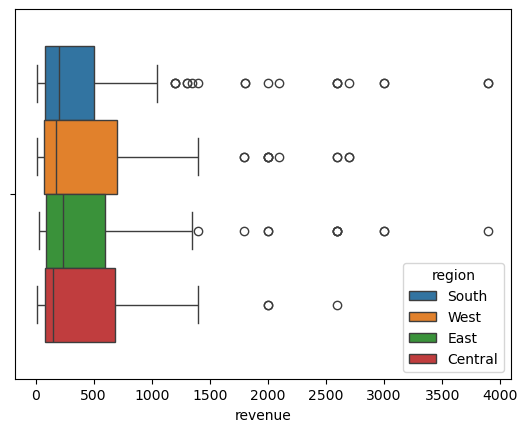

In [129]:
sns.boxplot(data=df,x='revenue',hue='region')

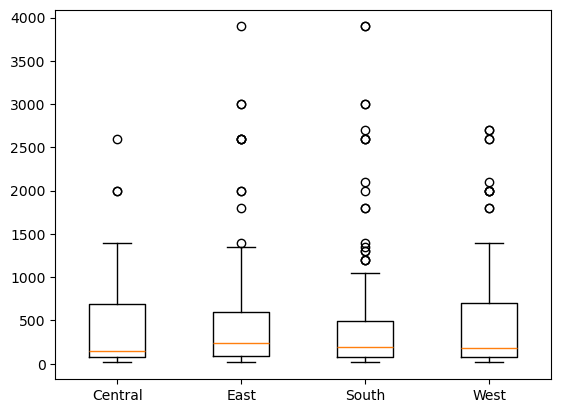

In [132]:
# Your code here
groups = df.groupby('region')['revenue']
data = [g for n,g in groups]
labels = [n for n,g in groups]

plt.boxplot(data,tick_labels=labels)
plt.show()

---

# Part 9: Business Insights (Putting It All Together)

## Task 9.1: Top Customers

Find the top 10 customers by total spending (sum of revenue).

Display: customer_id, full_name, city, membership, total_orders, total_revenue

Hint: You'll need to group by customer and aggregate.

In [135]:
# Your code here
df.groupby(['customer_id', 'full_name', 'city', 'membership']).agg(
    total_orders = ('order_id','count'),
    total_revenue = ('revenue','sum')
).reset_index().sort_values('total_revenue',ascending=False).head(10)


,customer_id,full_name,city,membership,total_orders,total_revenue
107,111,David Brown,San Antonio,Basic,7,6056.0
23,25,Jennifer Gonzalez,Phoenix,Gold,4,5970.0
72,74,Thomas Davis,Philadelphia,Gold,5,5678.0
129,134,Thomas Garcia,Houston,Gold,5,5463.0
111,115,Charles Davis,Philadelphia,Gold,5,5412.0
2,3,Robert Johnson,Los Angeles,Gold,5,5391.0
51,53,John Garcia,Los Angeles,Basic,4,5310.0
74,76,Sarah Hernandez,New York,Gold,4,5003.0
54,56,Richard Smith,Philadelphia,Gold,5,4893.0
24,26,Joseph Davis,Phoenix,Premium,5,4834.0


## Task 9.2: Best-Selling Products

Find the top 5 products by:
1. Total quantity sold
2. Total revenue generated

Are they the same products? Why or why not?

In [ ]:
# Your code here


## Task 9.3: Weekend vs Weekday Sales

Compare weekend vs weekday orders:
1. Number of orders
2. Total revenue
3. Average order value

When do customers spend more per order?

In [ ]:
# Your code here


## Task 9.4: Product Profitability Analysis

Calculate for each product:
1. Total revenue
2. Total profit
3. Profit margin percentage = (profit / revenue) * 100

Which products have the highest profit margin? Are high-revenue products also high-margin?

In [ ]:
# Your code here


---

# Part 10: Executive Summary

Based on your analysis, write a brief executive summary answering these questions:

1. **Overall Performance**: What is the total revenue and profit for TechMart in 2024?

2. **Top Product Category**: Which product category drives the most revenue?

3. **Customer Insights**: Which membership type is most valuable? Which region generates the most revenue?

4. **Seasonal Trends**: Are there any notable monthly or quarterly trends?

5. **Recommendations**: Based on your analysis, what would you recommend to TechMart's management?

In [ ]:
# Calculate summary statistics to support your summary


## Your Executive Summary

Write your summary here (double-click to edit):

1. **Overall Performance**: 
   - Total Revenue: $___
   - Total Profit: $___

2. **Top Product Category**: 

3. **Customer Insights**: 

4. **Seasonal Trends**: 

5. **Recommendations**: 


---

# Congratulations!

You have completed the TechMart E-Commerce Analysis case study!

## Skills Demonstrated

- [x] Loading and exploring data (head, tail, sample, info, describe)
- [x] Handling missing values and duplicates
- [x] Merging multiple DataFrames
- [x] Creating calculated columns
- [x] DateTime feature engineering
- [x] String operations
- [x] Using apply() with custom functions
- [x] Filtering with single and multiple conditions
- [x] Sorting data
- [x] GroupBy aggregations
- [x] Pivot tables
- [x] Data visualization (bar, line, histogram, box plots)
- [x] Business analysis and insights

## Next Steps

1. Try the `Pandas_Project/` folder for more practice
2. Apply these skills to your own datasets
3. Move on to Module 02: Data Exploration and Preparation